# Práctica 5 — Tarea 2: ¡Transfórmate en Super Saiyan!

**Escenario de aplicación.** Un *filtro interactivo* para la webcam inspirado en Dragon Ball, que reacciona a la **expresión de la cara** y a la **postura de las manos**. No usa ningún modelo entrenado por nosotros: todo se decide con **medidas geométricas entre landmarks** de MediaPipe (cara y manos), normalizadas por el tamaño de la cara o de la mano para que funcionen a cualquier distancia de la cámara.

| Nivel | Cómo se activa | Reacción |
|---|---|---|
| **0. Base** | Cara normal | Pelo negro (estado base) |
| **1. Super Saiyan** | **Cara de enfado**: cejas bajas y juntas respecto a la cara neutra | Pelo dorado y aura dorada alrededor de la cabeza |
| **2. Transformación** | Enfado **+ los dos puños cerrados por debajo de la barbilla** | Rayos eléctricos por la pantalla, temblor de imagen, aura más intensa y barra de poder |
| **3. Kamehameha** | **Manos juntas y abiertas** delante del cuerpo para cargar, y **abrir mucho la boca** (el grito) para disparar | Bola de energía que crece entre las manos y rayo hacia el lado de la pantalla o hacia la cámara |

Posibles usos: filtro para redes sociales o videollamadas, juego interactivo de gestos o demostrador de detección de expresiones y manos en tiempo real.

| Parte | Contenido |
|---|---|
| 1 | Detectores de cara y manos y prueba de los landmarks que se usan |
| 2 | Medidas, calibración, máquina de estados, efectos y prototipo con la webcam |
| 3 | GIF / vídeo final de la entrega |

Instalaciones previas

In [2]:
# Con el entorno VC_P5 ya está todo instalado (OpenCV, MediaPipe, NumPy, Matplotlib y Pillow)
%pip install mediapipe

Note: you may need to restart the kernel to use updated packages.


Paquetes necesarios

In [3]:
import os
import glob
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp

CONFIGURACIÓN (rutas y parámetros)

In [4]:
# Rutas (relativas a la carpeta TAREAS/)
CARPETA_MODELOS    = '../modelos'
CARPETA_RECURSOS   = '../img/recursos'       # PNG del pelo (los mismos que en la Tarea 1)
CARPETA_TEST_IMG   = '../img/test'
CARPETA_RESULTADOS = '../resultados/tarea2'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

FACE_LANDMARKER = os.path.join(CARPETA_MODELOS, 'face_landmarker.task')
HAND_LANDMARKER = os.path.join(CARPETA_MODELOS, 'hand_landmarker.task')
CAMARA = 0

# Pelo: mismos PNG y parámetros de colocación que en la Tarea 1
PELO_BASE = {'archivo': 'neutral.png', 'escala': 2.58, 'dy': 0.0, 'ancla': 0.57}
PELO_SSJ  = {'archivo': 'enfado.png',  'escala': 2.15, 'dy': 0.0, 'ancla': 0.66}

# Umbrales. Todas las medidas están normalizadas (por la distancia entre ojos, el alto de la cara
# o el tamaño de la palma), así que no dependen de lo cerca que se esté de la cámara.
SEG_CALIBRACION     = 2.0    # segundos de cara neutra al empezar
UMBRAL_IRA          = 0.10   # caída relativa de las cejas (respecto a la cara neutra) para entrar en enfado
UMBRAL_IRA_SALIR    = 0.06   # ... y para salir (histéresis)
UMBRAL_PUNO         = 1.35   # (distancia media puntas-muñeca / tamaño de la palma) por debajo = puño cerrado
PUNOS_NECESARIOS    = 2      # puños cerrados bajo la barbilla para la transformación
UMBRAL_MANOS_JUNTAS = 1.8    # distancia entre los centros de las manos / tamaño medio de la palma
UMBRAL_GRITO        = 0.08   # apertura de la boca (sobre la neutra) / alto de la cara
CARGA_MINIMA        = 0.5    # carga necesaria para poder disparar el Kamehameha
SEG_CARGA           = 2.0    # segundos para cargar el Kamehameha al máximo
SEG_DISPARO         = 2.0    # duración del rayo
FRAMES_ENTRAR, FRAMES_SALIR = 4, 8   # fotogramas seguidos para cambiar de estado (evita parpadeos)

---
# PARTE 1: DETECCIÓN

PASO 1.1: CARGAR LOS DETECTORES DE CARA Y MANOS

Se usan dos *tasks* de **MediaPipe**:

* **Face Landmarker**: 478 landmarks de la cara (una cara).
* **Hand Landmarker**: 21 landmarks por mano (hasta dos manos).

En el prototipo se crean en modo `VIDEO`, que aprovecha la información del fotograma anterior para seguir los puntos de forma más estable. Para las pruebas con imágenes fijas se usa el modo `IMAGE`. La función `detectar` devuelve los landmarks directamente en píxeles.

In [5]:
BaseOptions = mp.tasks.BaseOptions
vision = mp.tasks.vision
Modo = vision.RunningMode


def crear_detectores(modo):
    """Crea el detector de landmarks de la cara y el de las manos en el modo indicado (IMAGE o VIDEO)."""
    det_cara = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=FACE_LANDMARKER), running_mode=modo, num_faces=1))
    det_manos = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=HAND_LANDMARKER), running_mode=modo, num_hands=2,
        min_hand_detection_confidence=0.5, min_hand_presence_confidence=0.5, min_tracking_confidence=0.5))
    return det_cara, det_manos


def detectar(det_cara, det_manos, frame_bgr, t_ms=None):
    """Landmarks en píxeles: cara (478, 2) o None, y lista de manos, cada una (21, 2)."""
    alto, ancho = frame_bgr.shape[:2]
    imagen = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    if t_ms is None:
        res_cara, res_manos = det_cara.detect(imagen), det_manos.detect(imagen)
    else:
        res_cara, res_manos = det_cara.detect_for_video(imagen, t_ms), det_manos.detect_for_video(imagen, t_ms)
    cara = None
    if res_cara.face_landmarks:
        cara = np.array([(p.x * ancho, p.y * alto) for p in res_cara.face_landmarks[0]], np.float32)
    manos = [np.array([(p.x * ancho, p.y * alto) for p in m], np.float32) for m in res_manos.hand_landmarks]
    return cara, manos


print('Funciones de detección listas')

Funciones de detección listas


PASO 1.2: LANDMARKS QUE SE USAN Y PRUEBA SOBRE UNA IMAGEN

| Medida | Landmarks | Normalización | Para qué |
|---|---|---|---|
| Altura de las cejas | centro de la ceja (105, 334) → párpado superior (159, 386) | distancia entre ojos | Enfado: las cejas bajan |
| Separación de las cejas | extremos interiores (107, 336) | distancia entre ojos | Enfado: las cejas se juntan |
| Apertura de la boca | labio superior (13) → inferior (14) | alto de la cara (10 → 152) | Grito para disparar |
| Puño cerrado | puntas de los dedos (8, 12, 16, 20) → muñeca (0) | tamaño de la palma (0 → 9) | Puños de la transformación |
| Manos juntas | centro de cada mano (0, 5, 9, 13, 17) | tamaño medio de la palma | Carga del Kamehameha |
| Colocación del pelo | frente (10), barbilla (152), ojos, laterales (234, 454) | ancho de la cara | Pelo base y Super Saiyan |

Al dividir cada distancia por una medida de la propia cara o mano, los valores **no cambian al acercarse o alejarse de la cámara**.

In [6]:
# Índices de landmarks de la cara (MediaPipe Face Mesh)
OJO_IZQ, OJO_DER = [33, 133], [362, 263]
CEJA_IZQ, CEJA_DER = 105, 334                 # centro de cada ceja
PARPADO_IZQ, PARPADO_DER = 159, 386           # párpado superior
CEJA_INT_IZQ, CEJA_INT_DER = 107, 336         # extremo interior de las cejas
LABIO_SUP, LABIO_INF = 13, 14
FRENTE, BARBILLA, NARIZ = 10, 152, 1
CARA_IZQ, CARA_DER = 234, 454
PUNTOS_CARA = {'ceja': [CEJA_IZQ, CEJA_DER], 'parpado': [PARPADO_IZQ, PARPADO_DER],
               'entrecejo': [CEJA_INT_IZQ, CEJA_INT_DER], 'boca': [LABIO_SUP, LABIO_INF],
               'frente/barbilla': [FRENTE, BARBILLA], 'ojos': OJO_IZQ + OJO_DER, 'laterales': [CARA_IZQ, CARA_DER]}

# Índices de landmarks de la mano (MediaPipe Hands)
MUNECA, BASE_CORAZON = 0, 9
PUNTAS = [8, 12, 16, 20]
CENTRO_MANO = [0, 5, 9, 13, 17]
CONEXIONES_MANO = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (5, 9), (9, 10), (10, 11),
                   (11, 12), (9, 13), (13, 14), (14, 15), (15, 16), (13, 17), (17, 18), (18, 19), (19, 20), (0, 17)]


def dibujar_puntos_usados(img, cara, manos):
    colores = [(0, 255, 255), (255, 0, 255), (0, 128, 255), (0, 0, 255), (255, 255, 0), (0, 255, 0), (255, 128, 0)]
    if cara is not None:
        for (nombre, ids), col in zip(PUNTOS_CARA.items(), colores):
            for i in ids:
                x, y = cara[i].astype(int)
                cv2.circle(img, (x, y), 4, col, -1, cv2.LINE_AA)
                cv2.putText(img, str(i), (x + 5, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, col, 1, cv2.LINE_AA)
    for m in manos:
        for a, b in CONEXIONES_MANO:
            cv2.line(img, tuple(m[a].astype(int)), tuple(m[b].astype(int)), (0, 255, 0), 2, cv2.LINE_AA)
        for i in PUNTAS + [MUNECA]:
            cv2.circle(img, tuple(m[i].astype(int)), 5, (0, 0, 255), -1, cv2.LINE_AA)
    return img

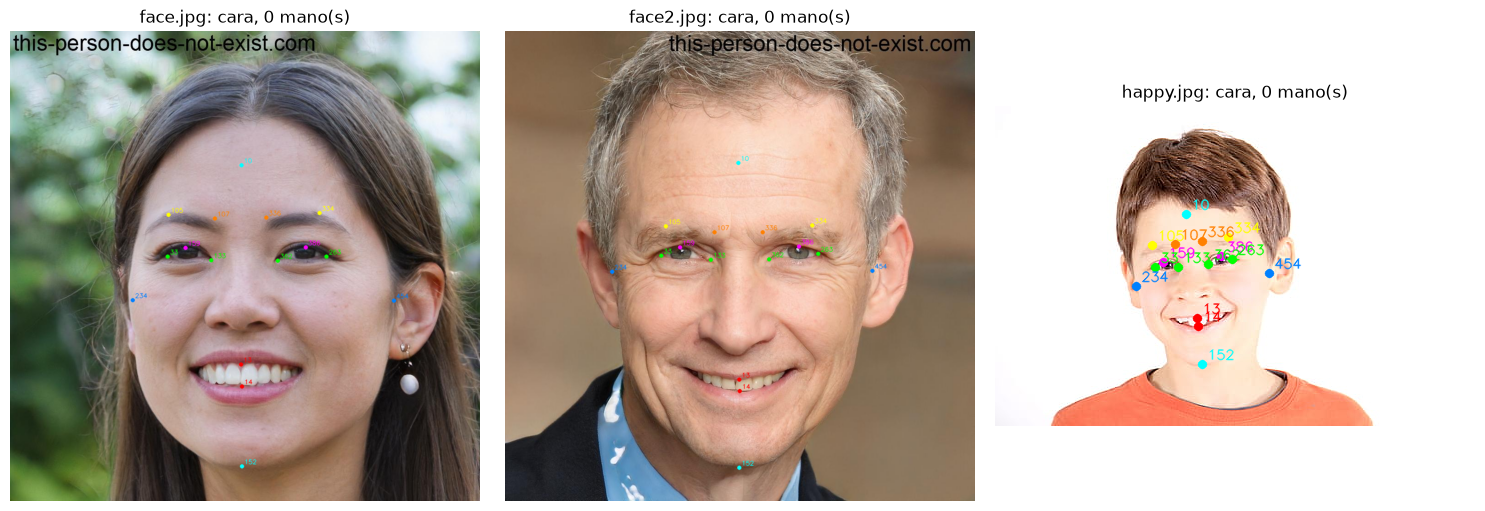

In [7]:
det_cara_img, det_manos_img = crear_detectores(Modo.IMAGE)
imagenes_test = sorted(f for f in os.listdir(CARPETA_TEST_IMG) if f.lower().endswith(('.jpg', '.png')))
plt.figure(figsize=(5 * len(imagenes_test), 5))
for k, nombre in enumerate(imagenes_test):
    img = cv2.imread(os.path.join(CARPETA_TEST_IMG, nombre))
    cara, manos = detectar(det_cara_img, det_manos_img, img)
    dibujar_puntos_usados(img, cara, manos)
    plt.subplot(1, len(imagenes_test), k + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off')
    plt.title(f'{nombre}: {"cara" if cara is not None else "sin cara"}, {len(manos)} mano(s)')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, 'landmarks_usados.png'), dpi=90)
plt.show()

---
# PARTE 2: PROTOTIPO

PASO 2.1: MEDIDAS Y CALIBRACIÓN

* **`medidas_cara`**: altura de las cejas, separación de las cejas y apertura de la boca, normalizadas (ver tabla del paso 1.2).
* **`medidas_mano`**: tamaño de la palma, cociente *dedos/palma* (≈ 2 con la mano abierta, ≈ 1 con el puño cerrado) y centro de la mano.
* **Calibración:** cada persona tiene unas cejas y una boca distintas, así que al empezar se piden **2 segundos de cara neutra** y se guarda la **mediana** de cada medida. El enfado y el grito se miden como **cambio relativo** respecto a esa referencia, lo que hace al prototipo mucho más robusto que un umbral fijo. Con la tecla `c` se puede repetir la calibración.
* **`senales`**: a partir de las medidas calcula, en cada fotograma:
  * **ira** = 0.65 · (caída relativa de la altura de las cejas) + 0.35 · (caída relativa de su separación),
  * **grito** = apertura de la boca − apertura neutra,
  * **puños abajo** = número de puños cerrados cuyo centro está por debajo de la barbilla,
  * **manos juntas** = dos manos abiertas cuyos centros están a menos de `UMBRAL_MANOS_JUNTAS` palmas de distancia.

In [8]:
def dist(a, b):
    return float(np.linalg.norm(np.asarray(a, np.float32) - np.asarray(b, np.float32)))


def medidas_cara(p):
    """Medidas normalizadas de la cara (no dependen de la distancia a la cámara)."""
    d_ojos = dist(p[OJO_IZQ].mean(0), p[OJO_DER].mean(0))
    alto = dist(p[FRENTE], p[BARBILLA])
    return {'cejas': (dist(p[CEJA_IZQ], p[PARPADO_IZQ]) + dist(p[CEJA_DER], p[PARPADO_DER])) / 2 / d_ojos,
            'entrecejo': dist(p[CEJA_INT_IZQ], p[CEJA_INT_DER]) / d_ojos,
            'boca': dist(p[LABIO_SUP], p[LABIO_INF]) / alto,
            'd_ojos': d_ojos, 'alto': alto}


def medidas_mano(m):
    palma = dist(m[MUNECA], m[BASE_CORAZON])
    dedos = float(np.mean([dist(m[i], m[MUNECA]) for i in PUNTAS])) / palma
    return {'palma': palma, 'dedos': dedos, 'puno': dedos < UMBRAL_PUNO, 'centro': m[CENTRO_MANO].mean(0)}


class Calibracion:
    """Guarda la mediana de las medidas de la cara neutra durante los primeros segundos."""
    def __init__(self, segundos=SEG_CALIBRACION):
        self.segundos = segundos
        self.reiniciar()

    def reiniciar(self):
        self.muestras, self.inicio, self.base = [], None, None

    @property
    def lista(self):
        return self.base is not None

    def actualizar(self, med, ahora):
        if self.lista or med is None:
            return
        self.inicio = self.inicio or ahora
        self.muestras.append([med['cejas'], med['entrecejo'], med['boca']])
        if ahora - self.inicio >= self.segundos and len(self.muestras) >= 10:
            cejas, entrecejo, boca = np.median(self.muestras, axis=0)
            self.base = {'cejas': cejas, 'entrecejo': entrecejo, 'boca': boca}

    def progreso(self, ahora):
        return 0.0 if self.inicio is None else min(1.0, (ahora - self.inicio) / self.segundos)


def senales(med, manos_med, cara, base):
    """Señales de cada fotograma a partir de las medidas y de la calibración."""
    ira = (0.65 * max(0.0, 1 - med['cejas'] / base['cejas'])
           + 0.35 * max(0.0, 1 - med['entrecejo'] / base['entrecejo']))
    barbilla_y = cara[BARBILLA][1]
    punos_abajo = sum(1 for m in manos_med if m['puno'] and m['centro'][1] > barbilla_y)
    juntas, separacion = False, None
    if len(manos_med) >= 2:
        a, b = manos_med[:2]
        separacion = dist(a['centro'], b['centro']) / ((a['palma'] + b['palma']) / 2)
        juntas = separacion < UMBRAL_MANOS_JUNTAS and not a['puno'] and not b['puno']
    return {'ira': ira, 'grito': med['boca'] - base['boca'], 'punos_abajo': punos_abajo,
            'manos_juntas': juntas, 'separacion': separacion}

PASO 2.2: MÁQUINA DE ESTADOS (con histéresis)

Las señales de un solo fotograma oscilan, así que no se cambia de estado directamente con ellas:

* La **ira** se suaviza con una media móvil exponencial y usa **dos umbrales** (`UMBRAL_IRA` para entrar y `UMBRAL_IRA_SALIR`, más bajo, para salir).
* Cada condición pasa por un **`Interruptor`**: solo se activa si se cumple `FRAMES_ENTRAR` fotogramas seguidos, y solo se desactiva tras `FRAMES_SALIR` fotogramas sin cumplirse. Así los efectos no parpadean.

Prioridad de los niveles: **Kamehameha** (manos juntas o disparando) > **Transformación** (enfado + puños) > **Super Saiyan** (enfado) > **Base**.

El **Kamehameha** tiene su propia lógica: mientras las manos están juntas la **carga** sube de 0 a 1 en `SEG_CARGA` segundos (si se separan, se descarga). Con al menos `CARGA_MINIMA` de carga, un **grito** dispara el rayo durante `SEG_DISPARO` segundos. La **dirección** se decide al disparar: si la bola está claramente a un lado de la cara, el rayo sale horizontal hacia ese lado. Si está delante, sale **hacia la cámara**.

In [9]:
class Interruptor:
    """Señal booleana con histéresis temporal."""
    def __init__(self, entrar=FRAMES_ENTRAR, salir=FRAMES_SALIR):
        self.entrar, self.salir, self.activo, self.cuenta = entrar, salir, False, 0

    def actualizar(self, condicion):
        if condicion != self.activo:
            self.cuenta += 1
            if self.cuenta >= (self.entrar if condicion else self.salir):
                self.activo, self.cuenta = condicion, 0
        else:
            self.cuenta = 0
        return self.activo


class Saiyan:
    """Estado del prototipo: nivel actual, poder, carga y disparo del Kamehameha."""
    def __init__(self):
        self.int_ira, self.int_transf, self.int_juntas = Interruptor(), Interruptor(), Interruptor(3, 6)
        self.ira = 0.0
        self.enfadado = self.transformado = self.juntas = False
        self.poder = self.carga = 0.0
        self.centro_bola, self.palma = None, 40.0
        self.inicio_disparo, self.fin_disparo, self.direccion = 0.0, 0.0, None
        self.nivel = 'BASE'

    def disparando(self, ahora):
        return ahora < self.fin_disparo

    def actualizar(self, s, manos_med, cara, ahora, dt):
        self.ira = 0.7 * self.ira + 0.3 * s['ira']
        umbral = UMBRAL_IRA_SALIR if self.enfadado else UMBRAL_IRA
        self.enfadado = self.int_ira.actualizar(self.ira > umbral)
        self.transformado = self.int_transf.actualizar(self.enfadado and s['punos_abajo'] >= PUNOS_NECESARIOS)
        self.juntas = self.int_juntas.actualizar(s['manos_juntas'])

        # Barra de poder: sube durante la transformación y baja poco a poco
        self.poder = float(np.clip(self.poder + (dt / 2.5 if self.transformado else -dt / 4), 0, 1))

        # Posición de la bola: punto medio entre las dos manos
        if len(manos_med) >= 2:
            a, b = manos_med[:2]
            nuevo = (a['centro'] + b['centro']) / 2
            self.centro_bola = nuevo if self.centro_bola is None else 0.5 * self.centro_bola + 0.5 * nuevo
            self.palma = (a['palma'] + b['palma']) / 2

        if self.disparando(ahora):
            pass
        elif self.fin_disparo and not self.disparando(ahora) and self.carga > 0 and self.inicio_disparo:
            self.carga, self.inicio_disparo = 0.0, 0.0          # el disparo ha terminado: se gasta la carga
        elif self.juntas:
            self.carga = min(1.0, self.carga + dt / SEG_CARGA)
            if self.carga >= CARGA_MINIMA and s['grito'] > UMBRAL_GRITO and self.centro_bola is not None:
                self.inicio_disparo, self.fin_disparo = ahora, ahora + SEG_DISPARO
                dx = self.centro_bola[0] - cara[NARIZ][0]
                ancho_cara = dist(cara[CARA_IZQ], cara[CARA_DER])
                self.direccion = np.array([np.sign(dx), 0.0]) if abs(dx) > 0.6 * ancho_cara else None
        else:
            self.carga = max(0.0, self.carga - dt / 0.8)

        if self.disparando(ahora) or (self.juntas and self.carga > 0):
            self.nivel = 'KAMEHAMEHA'
        elif self.transformado:
            self.nivel = 'TRANSFORMACION'
        elif self.enfadado:
            self.nivel = 'SUPER SAIYAN'
        else:
            self.nivel = 'BASE'
        return self.nivel

    @property
    def pelo_dorado(self):
        return self.enfadado or self.transformado or self.poder > 0.3

PASO 2.3: EFECTOS

* **Pelo** (`aplicar_pelo`): los PNG de la Tarea 1, anclados a la frente, escalados con el ancho de la cara y girados con la inclinación de los ojos.
* **Brillo** (`anadir_brillo`): las luces se dibujan en una capa negra, se difuminan con un filtro gaussiano (a mitad de resolución, para que sea rápido) y se **suman** al fotograma, como una luz.
* **Aura** (Super Saiyan y transformación): contorno ondulado alrededor de la cabeza y los hombros, con llamas que suben y se mueven con el tiempo. Su tamaño e intensidad crecen con el poder.
* **Rayos** (transformación): rayos en zigzag generados por **desplazamiento del punto medio** desde los bordes de la pantalla hacia el cuerpo. Cambian varias veces por segundo.
* **Temblor**: pequeña traslación de toda la imagen.
* **Kamehameha**: bola de energía azul con chispas que convergen. Al disparar, un rayo horizontal hasta el borde de la pantalla, o una explosión que crece hacia la cámara.
* **Texto**: "KA... ME... HA... ME..." según la carga y "¡¡HAAAAA!!" al disparar.

In [10]:
# ---------------------------------------------------------------- pelo (PNG con transparencia)
def cargar_png(ruta):
    img = cv2.imread(ruta, cv2.IMREAD_UNCHANGED)
    if img is None:
        print('⚠ No encontrado:', ruta, '(se dibujará sin pelo)')
        return None
    if img.shape[2] == 3:
        img = np.dstack([img, np.full(img.shape[:2], 255, np.uint8)])
    return img


PNG_BASE = cargar_png(os.path.join(CARPETA_RECURSOS, PELO_BASE['archivo']))
PNG_SSJ = cargar_png(os.path.join(CARPETA_RECURSOS, PELO_SSJ['archivo']))


def pegar_png(frame, png, cx, cy, ancho, angulo, ancla_y=0.5):
    """Pega un PNG escalado a 'ancho', girado 'angulo' grados y con su punto de anclaje en (cx, cy)."""
    h0, w0 = png.shape[:2]
    w, h = max(1, int(w0 * ancho / w0)), max(1, int(h0 * ancho / w0))
    img = cv2.resize(png, (w, h), interpolation=cv2.INTER_AREA)
    ax, ay = w / 2, ancla_y * h
    radio = max(np.hypot(px - ax, py - ay) for px, py in [(0, 0), (w, 0), (0, h), (w, h)])
    L = int(np.ceil(radio)) * 2 + 2
    lienzo = np.zeros((L, L, 4), np.uint8)
    ox, oy = int(L / 2 - ax), int(L / 2 - ay)
    lienzo[oy:oy + h, ox:ox + w] = img
    M = cv2.getRotationMatrix2D((L / 2, L / 2), -angulo, 1.0)
    lienzo = cv2.warpAffine(lienzo, M, (L, L), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0, 0))
    H, W = frame.shape[:2]
    x1, y1 = int(cx - L / 2), int(cy - L / 2)
    fx1, fy1, fx2, fy2 = max(0, x1), max(0, y1), min(W, x1 + L), min(H, y1 + L)
    if fx1 >= fx2 or fy1 >= fy2:
        return
    trozo = lienzo[fy1 - y1:fy2 - y1, fx1 - x1:fx2 - x1]
    alfa = trozo[..., 3:4].astype(np.float32) / 255
    roi = frame[fy1:fy2, fx1:fx2]
    roi[:] = (trozo[..., :3] * alfa + roi * (1 - alfa)).astype(np.uint8)


def aplicar_pelo(frame, p, dorado):
    png, cfg = (PNG_SSJ, PELO_SSJ) if dorado else (PNG_BASE, PELO_BASE)
    if png is None:
        return
    ojo_i, ojo_d = p[OJO_IZQ].mean(0), p[OJO_DER].mean(0)
    angulo = np.degrees(np.arctan2(ojo_d[1] - ojo_i[1], ojo_d[0] - ojo_i[0]))
    rad = np.radians(angulo)
    arriba = np.array([np.sin(rad), -np.cos(rad)])
    ancho = dist(p[CARA_IZQ], p[CARA_DER]) * cfg['escala']
    centro = p[FRENTE] + arriba * cfg['dy'] * dist(p[FRENTE], p[BARBILLA])
    pegar_png(frame, png, centro[0], centro[1], ancho, angulo, cfg['ancla'])


# ---------------------------------------------------------------- luz
def anadir_brillo(frame, capa, desenfoque=21, nitido=True):
    """Suma al fotograma una capa de luz difuminada (y, opcionalmente, la capa nítida encima)."""
    k = max(3, int(desenfoque) // 2 * 2 + 1)
    peq = cv2.resize(capa, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    peq = cv2.GaussianBlur(peq, (k, k), 0)
    brillo = cv2.resize(peq, (frame.shape[1], frame.shape[0]), interpolation=cv2.INTER_LINEAR)
    cv2.add(frame, brillo, dst=frame)
    if nitido:
        cv2.add(frame, capa, dst=frame)


def geometria_cara(p):
    ancho = dist(p[CARA_IZQ], p[CARA_DER])
    alto = dist(p[FRENTE], p[BARBILLA])
    return ancho, alto, (p[FRENTE] + p[BARBILLA]) / 2


# ---------------------------------------------------------------- aura
def dibujar_aura(frame, p, t, intensidad, color=(0, 190, 255)):
    ancho, alto, centro_cara = geometria_cara(p)
    centro = centro_cara + np.array([0, alto * 0.55])
    ang = np.linspace(0, 2 * np.pi, 120, endpoint=False)
    r = 1 + 0.08 * np.sin(7 * ang + t * 9) + 0.05 * np.sin(13 * ang - t * 13)
    llamas = np.clip(-np.sin(ang), 0, 1) ** 2                       # parte de arriba
    r = r + (0.25 + 0.25 * intensidad) * llamas * (0.6 + 0.4 * np.sin(t * 15 + ang * 9))
    ax, ay = ancho * (1.25 + 0.35 * intensidad), alto * (1.35 + 0.35 * intensidad)
    pts = np.stack([centro[0] + ax * r * np.cos(ang), centro[1] + ay * r * np.sin(ang)], 1).astype(np.int32)
    capa = np.zeros_like(frame)
    grosor = max(3, int(ancho * (0.10 + 0.12 * intensidad)))
    col = tuple(int(c * (0.6 + 0.4 * intensidad)) for c in color)
    cv2.polylines(capa, [pts], True, col, grosor, cv2.LINE_AA)
    anadir_brillo(frame, capa, desenfoque=ancho * 0.3, nitido=False)
    return centro, ax, ay


# ---------------------------------------------------------------- rayos
def zigzag(a, b, rng, desvio, niveles=5):
    """Rayo por desplazamiento del punto medio: cada segmento se parte en dos y el medio se desvía."""
    pts = [np.asarray(a, np.float32), np.asarray(b, np.float32)]
    for _ in range(niveles):
        nuevos = [pts[0]]
        for p, q in zip(pts[:-1], pts[1:]):
            normal = np.array([p[1] - q[1], q[0] - p[0]], np.float32)
            n = np.linalg.norm(normal)
            medio = (p + q) / 2 + (normal / n * rng.normal(0, desvio) if n > 0 else 0)
            nuevos += [medio, q]
        pts, desvio = nuevos, desvio / 2
    return np.array(pts, np.int32)


def dibujar_rayos(frame, p, t, n=6):
    alto_img, ancho_img = frame.shape[:2]
    ancho, alto, centro_cara = geometria_cara(p)
    cuerpo = centro_cara + np.array([0, alto * 0.6])
    rng = np.random.default_rng(int(t * 10))                       # cambian 10 veces por segundo
    capa = np.zeros_like(frame)
    grosor = max(1, int(ancho / 90))
    for _ in range(n):
        lado = rng.integers(4)
        u = rng.uniform(0, 1)
        origen = [(u * ancho_img, 0), (ancho_img, u * alto_img), (u * ancho_img, alto_img), (0, u * alto_img)][lado]
        destino = cuerpo + rng.normal(0, 1, 2) * np.array([ancho * 0.7, alto * 0.6])
        pts = zigzag(origen, destino, rng, desvio=dist(origen, destino) * 0.12)
        cv2.polylines(capa, [pts], False, (200, 120, 40), grosor * 5, cv2.LINE_AA)
        cv2.polylines(frame, [pts], False, (255, 255, 255), grosor, cv2.LINE_AA)
    # chispas cortas sobre el contorno del aura (alrededor de la cabeza y los hombros)
    centro_aura, ax, ay = centro_cara + np.array([0, alto * 0.55]), ancho * 1.5, alto * 1.6
    for _ in range(5):
        a_ang = rng.uniform(0, 2 * np.pi)
        a = centro_aura + np.array([ax * np.cos(a_ang), ay * np.sin(a_ang)])
        b = a + rng.normal(0, 1, 2) * ancho * 0.3
        pts = zigzag(a, b, rng, desvio=ancho * 0.05, niveles=3)
        cv2.polylines(capa, [pts], False, (200, 120, 40), grosor * 4, cv2.LINE_AA)
        cv2.polylines(frame, [pts], False, (255, 255, 255), grosor, cv2.LINE_AA)
    anadir_brillo(frame, capa, desenfoque=ancho * 0.12, nitido=False)


def temblor(frame, t, fuerza):
    if fuerza <= 0:
        return frame
    dx, dy = fuerza * np.sin(t * 53), fuerza * np.cos(t * 47)
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(frame, M, (frame.shape[1], frame.shape[0]), borderMode=cv2.BORDER_REFLECT)


# ---------------------------------------------------------------- Kamehameha
AZUL_OSCURO, AZUL, AZUL_CLARO, BLANCO = (255, 120, 20), (255, 190, 80), (255, 235, 170), (255, 255, 255)


def dibujar_bola(frame, c, r, t):
    c = tuple(np.asarray(c).astype(int))
    r = max(3, r * (1 + 0.08 * np.sin(t * 25)))
    capa = np.zeros_like(frame)
    cv2.circle(capa, c, int(r * 1.9), AZUL_OSCURO, -1, cv2.LINE_AA)
    anadir_brillo(frame, capa, desenfoque=r * 1.6, nitido=False)
    rng = np.random.default_rng(3)
    for k in range(16):                                              # chispas que convergen
        fase = (t * 1.3 + k / 16) % 1.0
        a = rng.uniform(0, 2 * np.pi)
        rr = r * (4.0 - 3.0 * fase)
        q = (int(c[0] + rr * np.cos(a)), int(c[1] + rr * np.sin(a)))
        cv2.circle(frame, q, max(1, int(r * 0.09)), AZUL_CLARO, -1, cv2.LINE_AA)
    nucleo = np.zeros_like(frame)
    cv2.circle(nucleo, c, int(r), AZUL, -1, cv2.LINE_AA)
    cv2.circle(nucleo, c, int(r * 0.6), BLANCO, -1, cv2.LINE_AA)
    anadir_brillo(frame, nucleo, desenfoque=r * 0.4, nitido=True)


def dibujar_rayo_lateral(frame, c, direccion, r, t, progreso):
    alto_img, ancho_img = frame.shape[:2]
    c = np.asarray(c, np.float32)
    fin = c + direccion * np.hypot(ancho_img, alto_img) * min(1.0, progreso * 5)
    grosor = r * (0.9 + 0.1 * np.sin(t * 35)) * (1 - 0.4 * max(0, progreso - 0.8) / 0.2)
    p1, p2 = tuple(c.astype(int)), tuple(fin.astype(int))
    capa = np.zeros_like(frame)
    cv2.line(capa, p1, p2, AZUL_OSCURO, int(grosor * 2.0), cv2.LINE_AA)
    anadir_brillo(frame, capa, desenfoque=grosor * 1.5, nitido=False)
    nucleo = np.zeros_like(frame)
    cv2.line(nucleo, p1, p2, AZUL, int(grosor * 1.3), cv2.LINE_AA)
    cv2.line(nucleo, p1, p2, BLANCO, max(2, int(grosor * 0.6)), cv2.LINE_AA)
    cv2.circle(nucleo, p1, int(grosor * 1.2), BLANCO, -1, cv2.LINE_AA)
    anadir_brillo(frame, nucleo, desenfoque=grosor * 0.3, nitido=True)


def dibujar_rayo_frontal(frame, c, r, t, progreso):
    c = tuple(np.asarray(c).astype(int))
    crece = min(1.0, progreso * 2.5) ** 0.7
    R = (r * 1.3 + crece * 0.35 * min(frame.shape[:2])) * (1 + 0.05 * np.sin(t * 30)) * (1 - 0.3 * max(0, progreso - 0.8) / 0.2)
    capa = np.zeros_like(frame)
    cv2.circle(capa, c, int(R), AZUL_OSCURO, -1, cv2.LINE_AA)
    anadir_brillo(frame, capa, desenfoque=R * 0.6, nitido=False)
    nucleo = np.zeros_like(frame)
    cv2.circle(nucleo, c, int(R * 0.65), AZUL, -1, cv2.LINE_AA)
    cv2.circle(nucleo, c, int(R * 0.4), BLANCO, -1, cv2.LINE_AA)
    anadir_brillo(frame, nucleo, desenfoque=R * 0.2, nitido=True)
    if progreso < 0.1:                                               # fogonazo inicial
        a = 0.5 * (1 - progreso / 0.1)
        cv2.addWeighted(np.full_like(frame, 255), a, frame, 1 - a, 0, dst=frame)


# ---------------------------------------------------------------- texto e interfaz
def texto(frame, txt, centro_x, y, escala, color, grosor=3):
    fuente = cv2.FONT_HERSHEY_DUPLEX
    (w, h), _ = cv2.getTextSize(txt, fuente, escala, grosor)
    x = int(centro_x - w / 2)
    cv2.putText(frame, txt, (x, y), fuente, escala, (0, 0, 0), grosor + 5, cv2.LINE_AA)
    cv2.putText(frame, txt, (x, y), fuente, escala, color, grosor, cv2.LINE_AA)


def barra(frame, x, y, ancho, alto, valor, color, etiqueta=None, marca=None):
    cv2.rectangle(frame, (x, y), (x + ancho, y + alto), (40, 40, 40), -1)
    cv2.rectangle(frame, (x, y), (x + int(ancho * float(np.clip(valor, 0, 1))), y + alto), color, -1)
    if marca is not None:
        xm = x + int(ancho * marca)
        cv2.line(frame, (xm, y - 2), (xm, y + alto + 2), (255, 255, 255), 2)
    cv2.rectangle(frame, (x, y), (x + ancho, y + alto), (255, 255, 255), 1)
    if etiqueta:
        cv2.putText(frame, etiqueta, (x + ancho + 8, y + alto - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                    (255, 255, 255), 1, cv2.LINE_AA)


COLOR_NIVEL = {'BASE': (200, 200, 200), 'SUPER SAIYAN': (0, 215, 255), 'TRANSFORMACION': (0, 140, 255),
               'KAMEHAMEHA': (255, 200, 60)}

PASO 2.4: FUNCIÓN DE CADA FOTOGRAMA

`procesar` junta todo: medidas → calibración → señales → estado → efectos. Se separa en dos partes para poder probar los efectos sin webcam:

* **`procesar`**: calcula las medidas y actualiza el estado.
* **`dibujar_escena`**: dibuja los efectos del estado actual. El orden importa: primero el aura y los rayos, luego el pelo (encima del aura), después el Kamehameha y los textos, y por último el temblor de toda la imagen.

Con `debug=True` (tecla `d`) se muestran los landmarks usados y las barras de cada señal con su umbral, muy útil para ajustar los umbrales a cada persona y cámara.

In [11]:
def dibujar_escena(frame, cara, estado, t, ahora):
    ancho_img = frame.shape[1]
    if estado.nivel in ('SUPER SAIYAN', 'TRANSFORMACION') or estado.poder > 0.05:
        dibujar_aura(frame, cara, t, intensidad=max(0.3 if estado.enfadado else 0.0, estado.poder))
    if estado.nivel == 'TRANSFORMACION':
        dibujar_rayos(frame, cara, t, n=4 + int(6 * estado.poder))
    aplicar_pelo(frame, cara, estado.pelo_dorado)

    fuerza = 0.0
    if estado.centro_bola is not None and estado.nivel == 'KAMEHAMEHA':
        r = estado.palma * (0.3 + 0.6 * estado.carga)
        if estado.disparando(ahora):
            progreso = (ahora - estado.inicio_disparo) / SEG_DISPARO
            if estado.direccion is not None:
                dibujar_rayo_lateral(frame, estado.centro_bola, estado.direccion, r, t, progreso)
            else:
                dibujar_rayo_frontal(frame, estado.centro_bola, r, t, progreso)
            texto(frame, 'HAAAAAA!!', ancho_img / 2, 70, 2.0, (255, 255, 255), 4)
            fuerza = 10 * (1 - progreso)
        else:
            dibujar_bola(frame, estado.centro_bola, r, t)
            silabas = ['KA...', 'KA... ME...', 'KA... ME... HA...', 'KA... ME... HA... ME...']
            texto(frame, silabas[min(3, int(estado.carga * 4))], ancho_img / 2, 60, 1.3, AZUL_CLARO, 3)
            if estado.carga >= CARGA_MINIMA:
                texto(frame, 'Abre la boca para disparar!', ancho_img / 2, 100, 0.8, (255, 255, 255), 2)
    elif estado.nivel == 'TRANSFORMACION':
        texto(frame, 'AAAAAAAH!!', ancho_img / 2, 70, 1.8, (0, 215, 255), 4)
        fuerza = 3 + 5 * estado.poder

    # nivel y barra de poder
    cv2.putText(frame, estado.nivel, (12, frame.shape[0] - 20), cv2.FONT_HERSHEY_DUPLEX, 0.9, (0, 0, 0), 5, cv2.LINE_AA)
    cv2.putText(frame, estado.nivel, (12, frame.shape[0] - 20), cv2.FONT_HERSHEY_DUPLEX, 0.9,
                COLOR_NIVEL[estado.nivel], 2, cv2.LINE_AA)
    if estado.poder > 0:
        barra(frame, 12, frame.shape[0] - 55, 200, 14, estado.poder, (0, 200, 255), 'PODER')
    return temblor(frame, t, fuerza)


def dibujar_debug(frame, cara, manos, manos_med, s, estado):
    dibujar_puntos_usados(frame, cara, manos)
    for m in manos_med:
        x, y = m['centro'].astype(int)
        cv2.putText(frame, f"{'PUNO' if m['puno'] else 'abierta'} {m['dedos']:.2f}", (x - 40, y + 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1, cv2.LINE_AA)
    capa = frame.copy()
    x0 = frame.shape[1] - 340                                        # panel arriba a la derecha
    cv2.rectangle(capa, (x0 - 7, 35), (frame.shape[1] - 5, 170), (0, 0, 0), -1)
    cv2.addWeighted(capa, 0.5, frame, 0.5, 0, dst=frame)
    barra(frame, x0, 45, 180, 12, estado.ira / (2 * UMBRAL_IRA), (0, 0, 255), f'ira {estado.ira:.2f}', marca=0.5)
    barra(frame, x0, 67, 180, 12, s['punos_abajo'] / 2, (0, 140, 255), f"punos abajo {s['punos_abajo']}")
    sep = s['separacion']
    barra(frame, x0, 89, 180, 12, 0 if sep is None else UMBRAL_MANOS_JUNTAS / max(sep, 1e-3) / 2, (255, 200, 60),
          'manos juntas' if s['manos_juntas'] else 'manos separadas', marca=0.5)
    barra(frame, x0, 111, 180, 12, s['grito'] / (2 * UMBRAL_GRITO), (255, 255, 255), f"grito {s['grito']:.2f}", marca=0.5)
    barra(frame, x0, 133, 180, 12, estado.carga, (255, 120, 20), f'carga {estado.carga:.2f}',
          marca=CARGA_MINIMA)


def procesar(frame, cara, manos, estado, calib, t, ahora, dt, debug=False):
    """Procesa un fotograma: devuelve la imagen con los efectos."""
    ancho_img = frame.shape[1]
    if cara is None:
        texto(frame, 'No se detecta ninguna cara', ancho_img / 2, 50, 0.9, (0, 0, 255), 2)
        return frame
    med = medidas_cara(cara)
    if not calib.lista:
        calib.actualizar(med, ahora)
        aplicar_pelo(frame, cara, False)
        texto(frame, 'Calibrando: pon cara normal', ancho_img / 2, 50, 0.9, (255, 255, 255), 2)
        barra(frame, int(ancho_img / 2 - 120), 70, 240, 14, calib.progreso(ahora), (0, 255, 0))
        return frame
    manos_med = [medidas_mano(m) for m in manos]
    s = senales(med, manos_med, cara, calib.base)
    estado.actualizar(s, manos_med, cara, ahora, dt)
    frame = dibujar_escena(frame, cara, estado, t, ahora)
    if debug:
        dibujar_debug(frame, cara, manos, manos_med, s, estado)
    return frame

PASO 2.5: PRUEBA DE LOS EFECTOS SOBRE UNA IMAGEN

Antes de abrir la webcam se comprueba que cada efecto se dibuja bien. Como las imágenes de prueba no tienen manos, se **fuerza el estado** y se colocan unas manos simuladas delante del pecho.

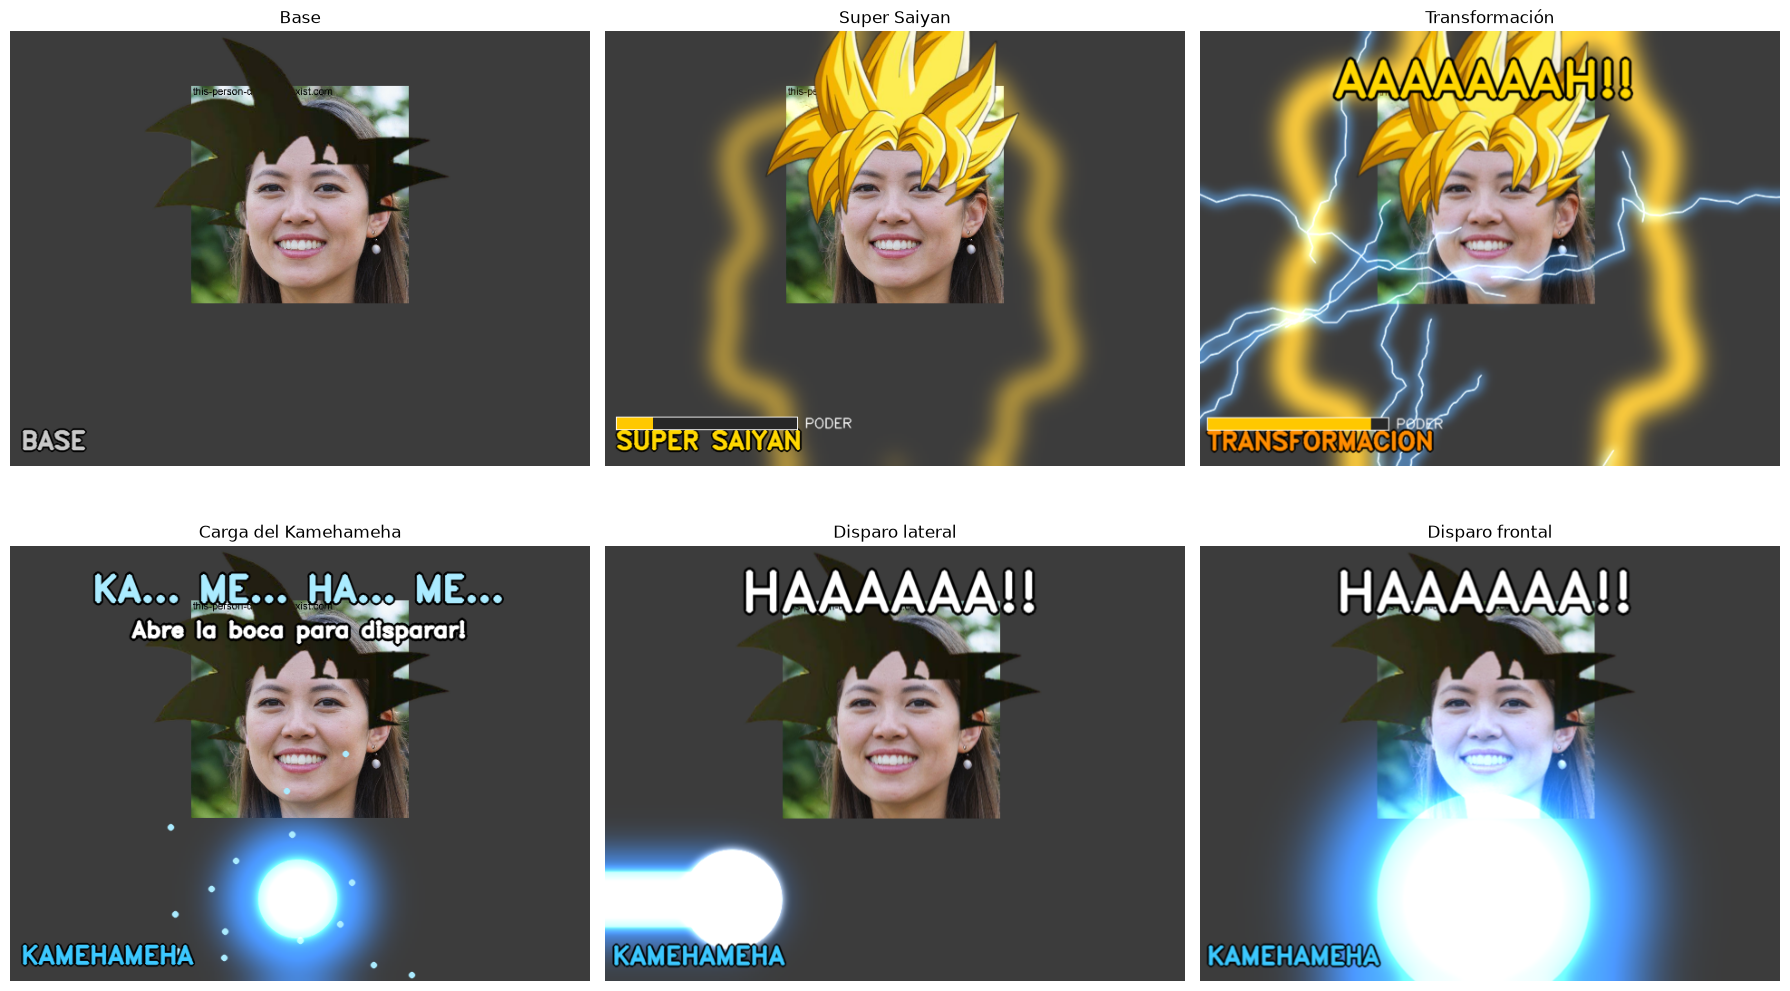

In [12]:
def estado_forzado(nivel, cara, carga=0.0, poder=0.0, disparo=None, direccion=None):
    e = Saiyan()
    e.nivel = nivel
    e.enfadado = nivel in ('SUPER SAIYAN', 'TRANSFORMACION')
    e.transformado = nivel == 'TRANSFORMACION'
    e.poder, e.carga = poder, carga
    ancho, alto, centro = geometria_cara(cara)
    e.centro_bola = centro + np.array([direccion * 1.3 * ancho if direccion is not None else 0, 1.2 * alto])
    e.palma = ancho * 0.45
    if disparo is not None:                         # disparo empezado hace 'disparo' segundos
        e.inicio_disparo, e.fin_disparo = 100.0 - disparo, 100.0 - disparo + SEG_DISPARO
        e.direccion = None if direccion is None else np.array([direccion, 0.0])
    return e


# Se reduce la foto y se rellena el borde para simular que la persona está más lejos, como con la webcam
img = cv2.imread(os.path.join(CARPETA_TEST_IMG, 'face.jpg'))
img = cv2.resize(img, (240, int(img.shape[0] * 240 / img.shape[1])))
img = cv2.copyMakeBorder(img, 60, 480 - 60 - img.shape[0], 200, 200, cv2.BORDER_CONSTANT, value=(60, 60, 60))
cara, _ = detectar(det_cara_img, det_manos_img, img)
casos = [('Base', estado_forzado('BASE', cara)),
         ('Super Saiyan', estado_forzado('SUPER SAIYAN', cara, poder=0.2)),
         ('Transformación', estado_forzado('TRANSFORMACION', cara, poder=0.9)),
         ('Carga del Kamehameha', estado_forzado('KAMEHAMEHA', cara, carga=0.8)),
         ('Disparo lateral', estado_forzado('KAMEHAMEHA', cara, carga=1.0, disparo=0.6, direccion=-1)),
         ('Disparo frontal', estado_forzado('KAMEHAMEHA', cara, carga=1.0, disparo=0.4))]
plt.figure(figsize=(18, 11))
for k, (titulo, e) in enumerate(casos):
    salida = dibujar_escena(img.copy(), cara, e, t=0.7, ahora=100.0)
    plt.subplot(2, 3, k + 1)
    plt.imshow(cv2.cvtColor(salida, cv2.COLOR_BGR2RGB)); plt.title(titulo); plt.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, 'prueba_efectos.png'), dpi=80)
plt.show()

PASO 2.6: PROTOTIPO CON LA WEBCAM

Al empezar, mira a la cámara con **cara normal durante 2 segundos** para calibrar. Para que se vean los puños y las manos, **colócate a una distancia a la que salga el torso** en la imagen.

| Acción | Cómo |
|---|---|
| Super Saiyan | Cara de enfado: frunce el ceño y baja las cejas |
| Transformación | Enfado + **los dos puños cerrados por debajo de la barbilla** (como apretando hacia abajo) |
| Cargar el Kamehameha | **Junta las manos abiertas** delante del cuerpo o a un lado (como sujetando una bola) |
| Disparar | Con la carga a la mitad o más, **abre mucho la boca**. Si la bola está a un lado de la cara, el rayo sale hacia ese lado. Si está delante, sale hacia la cámara |

| Tecla | Acción |
|---|---|
| `d` | Muestra u oculta los landmarks y las barras de las señales (modo *debug*) |
| `c` | Repite la calibración de la cara neutra |
| `g` | Empieza o termina la grabación de un clip en `../resultados/tarea2/` (para el GIF de la entrega) |
| `Esc` | Salir |

In [18]:
cap = cv2.VideoCapture(CAMARA)
det_cara, det_manos = crear_detectores(Modo.VIDEO)
estado, calib = Saiyan(), Calibracion()
debug, grabador = False, None
n_clip = len(glob.glob(os.path.join(CARPETA_RESULTADOS, 'clip_tarea2_*.mp4')))
t_inicio = t_prev = time.time()
ultimo_ms, fps = -1, 0.0

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            print('No se pudo leer de la cámara'); break
        frame = cv2.flip(frame, 1)                                   # efecto espejo
        ahora = time.time()
        dt, t_prev = min(0.1, ahora - t_prev), ahora
        t = ahora - t_inicio
        t_ms = max(int(t * 1000), ultimo_ms + 1)                      # MediaPipe exige tiempos crecientes
        ultimo_ms = t_ms

        cara, manos = detectar(det_cara, det_manos, frame, t_ms)
        salida = procesar(frame, cara, manos, estado, calib, t, ahora, dt, debug)

        fps = 0.9 * fps + 0.1 / max(dt, 1e-3)
        if grabador is not None:
            grabador.write(salida)
        vista = salida.copy()
        cv2.putText(vista, f'{fps:.0f} fps', (vista.shape[1] - 90, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                    (255, 255, 255), 1, cv2.LINE_AA)
        if grabador is not None:
            cv2.circle(vista, (vista.shape[1] - 110, 20), 8, (0, 0, 255), -1)
        cv2.imshow('P5 Tarea 2 - Super Saiyan', vista)

        tecla = cv2.waitKey(1) & 0xFF
        if tecla == 27:
            break
        elif tecla == ord('d'):
            debug = not debug
        elif tecla == ord('c'):
            calib.reiniciar(); estado = Saiyan()
        elif tecla == ord('g'):
            if grabador is None:
                ruta = os.path.join(CARPETA_RESULTADOS, f'clip_tarea2_{n_clip}.mp4'); n_clip += 1
                grabador = cv2.VideoWriter(ruta, cv2.VideoWriter_fourcc(*'mp4v'), 20,
                                           (salida.shape[1], salida.shape[0]))
                print('Grabando en', ruta)
            else:
                grabador.release(); grabador = None
                print('Grabación terminada')
finally:
    cap.release()
    det_cara.close(); det_manos.close()
    if grabador is not None:
        grabador.release()
    cv2.destroyAllWindows()

Grabando en ../resultados/tarea2\clip_tarea2_0.mp4


---
# PARTE 3: ENTREGA

PASO 3.1: GIF / VÍDEO FINAL (máximo 30 s, con momentos de los dos prototipos)

Se juntan los clips grabados con la tecla `g` en las dos tareas (`../resultados/tarea1/clip_tarea1_*.mp4` y `../resultados/tarea2/clip_tarea2_*.mp4`) y se generan:

* `../resultados/entrega.mp4`: vídeo de 30 s como máximo.
* `../resultados/entrega.gif`: la misma selección en GIF (más pequeño y a menos fotogramas por segundo, para que no pese demasiado).

Por defecto se reparte el tiempo a partes iguales entre los clips, empezando por el principio de cada uno. Para elegir los mejores momentos, indica en `TRAMOS` el segundo de inicio y de fin de cada clip, por ejemplo `{'clip_tarea1_0.mp4': (3, 12)}`.

In [19]:
from PIL import Image

DURACION_MAX = 30          # segundos
FPS_VIDEO, FPS_GIF = 20, 10
ANCHO_VIDEO, ANCHO_GIF = 640, 400
TRAMOS = {}                # {'nombre_clip.mp4': (inicio_s, fin_s)} para elegir los mejores momentos

clips = (sorted(glob.glob('../resultados/tarea1/clip_tarea1_*.mp4'))
         + sorted(glob.glob('../resultados/tarea2/clip_tarea2_*.mp4')))
print('Clips encontrados:', [os.path.basename(c) for c in clips])

seg_por_clip = DURACION_MAX / max(1, len(clips))
fotogramas, alto_video = [], None
for ruta in clips:
    nombre = os.path.basename(ruta)
    cap_clip = cv2.VideoCapture(ruta)
    fps_clip = cap_clip.get(cv2.CAP_PROP_FPS) or 20
    ini, fin = TRAMOS.get(nombre, (0, seg_por_clip))
    paso, siguiente, i = fps_clip / FPS_VIDEO, ini * fps_clip, 0
    while True:
        ok, f = cap_clip.read()
        if not ok or i >= fin * fps_clip:
            break
        if i >= siguiente:
            alto_video = alto_video or int(round(f.shape[0] * ANCHO_VIDEO / f.shape[1] / 2) * 2)
            fotogramas.append(cv2.resize(f, (ANCHO_VIDEO, alto_video), interpolation=cv2.INTER_AREA))
            siguiente += paso
        i += 1
    cap_clip.release()
fotogramas = fotogramas[:DURACION_MAX * FPS_VIDEO]

if fotogramas:
    ruta_mp4 = '../resultados/entrega.mp4'
    escritor = cv2.VideoWriter(ruta_mp4, cv2.VideoWriter_fourcc(*'mp4v'), FPS_VIDEO, (ANCHO_VIDEO, alto_video))
    for f in fotogramas:
        escritor.write(f)
    escritor.release()

    alto_gif = int(alto_video * ANCHO_GIF / ANCHO_VIDEO)
    gif = [Image.fromarray(cv2.cvtColor(cv2.resize(f, (ANCHO_GIF, alto_gif), interpolation=cv2.INTER_AREA),
                                        cv2.COLOR_BGR2RGB)).quantize(colors=128)
           for f in fotogramas[::FPS_VIDEO // FPS_GIF]]
    ruta_gif = '../resultados/entrega.gif'
    gif[0].save(ruta_gif, save_all=True, append_images=gif[1:], duration=int(1000 / FPS_GIF), loop=0, optimize=True)
    print(f'{len(fotogramas) / FPS_VIDEO:.1f} s -> {ruta_mp4} ({os.path.getsize(ruta_mp4) / 1e6:.1f} MB) '
          f'y {ruta_gif} ({os.path.getsize(ruta_gif) / 1e6:.1f} MB)')
else:
    print('No hay clips: graba alguno con la tecla g en el prototipo de cada tarea')

Clips encontrados: ['clip_tarea2_0.mp4']
18.6 s -> ../resultados/entrega.mp4 (4.8 MB) y ../resultados/entrega.gif (11.2 MB)
